# Deep Learning, Phase 1, Day 1: Neuron, Activations and the Forward Pass


In [1]:
import numpy as np, pandas as pd
import matplotlib.pyplot as plt, seaborn as sns
from sklearn.datasets import make_moons
from sklearn.linear_model import LogisticRegression
sns.set_theme(style='whitegrid')
np.random.seed(42)

## 1. One neuron
A neuron takes inputs `x`, multiplies each by a **weight** `w`, adds a **bias** `b`, and passes the result through an **activation function** `f`:

**output = f(w1*x1 + w2*x2 + ... + b)**

- **Weights** say how important each input is. **Bias** shifts the result up or down.
- Weights and bias are the **parameters** the network learns. (Same idea as the slope and intercept in linear regression from Week 1.)
- Without the activation, one neuron is just linear regression.

Calculate one neuron by hand first:

In [2]:
x = np.array([2.0, 3.0])       # two input features
w = np.array([0.5, -1.0])      # weights
b = 0.1                        # bias

z = np.dot(w, x) + b           # weighted sum: 2*0.5 + 3*(-1) + 0.1
print('z =', z)

z = -1.9


## 2. Activation functions
| Activation | Formula | Output range | Typical use |
|---|---|---|---|
| **Sigmoid** | 1 / (1 + e^-z) | 0 to 1 | output layer of a binary classifier (a probability) |
| **Tanh** | (e^z - e^-z) / (e^z + e^-z) | -1 to 1 | hidden layers (older networks), zero-centred |
| **ReLU** | max(0, z) | 0 to infinity | default for hidden layers: simple and fast |

z = -1.9
sigmoid(z) = 0.1301
tanh(z)    = -0.9562
relu(z)    = 0.0000


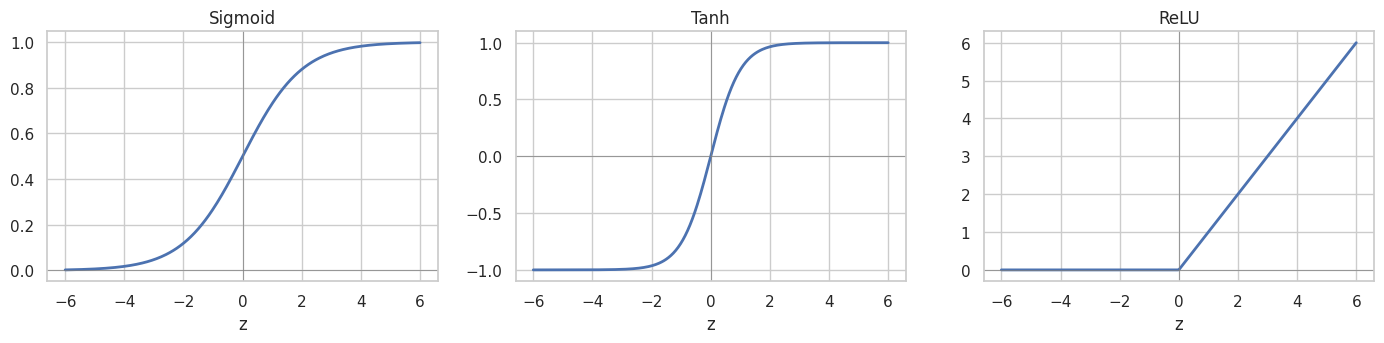

In [3]:
def sigmoid(z): return 1 / (1 + np.exp(-z))
def tanh(z):    return np.tanh(z)
def relu(z):    return np.maximum(0, z)

print(f'z = {z}')
print(f'sigmoid(z) = {sigmoid(z):.4f}')
print(f'tanh(z)    = {tanh(z):.4f}')
print(f'relu(z)    = {relu(z):.4f}')

zs = np.linspace(-6, 6, 300)
fig, ax = plt.subplots(1, 3, figsize=(14, 3.6), sharex=True)
for a, f, name in zip(ax, [sigmoid, tanh, relu], ['Sigmoid', 'Tanh', 'ReLU']):
    a.plot(zs, f(zs), lw=2); a.axhline(0, color='grey', lw=.5); a.axvline(0, color='grey', lw=.5); a.set_title(name); a.set_xlabel('z')
plt.tight_layout(); plt.show()

## 3. From one neuron to a layer: shapes
A **layer** is many neurons looking at the same inputs. We compute all of them at once with matrix multiplication:

**Z = X @ W + b**, then **A = f(Z)**

| Symbol | Shape | Meaning |
|---|---|---|
| `X` | (n_samples, n_inputs) | the data, one row per sample |
| `W` | (n_inputs, n_neurons) | one column of weights per neuron |
| `b` | (n_neurons,) | one bias per neuron |
| `Z`, `A` | (n_samples, n_neurons) | layer output |

Most bugs in neural networks are shape mistakes, so always print the shapes.

In [4]:
X = np.array([[2.0, 3.0],
              [1.0, -1.0],
              [0.0, 4.0]])               # 3 samples, 2 features
W = np.array([[0.5, 1.0, -0.5],
              [-1.0, 0.2, 0.8]])         # 2 inputs -> 3 neurons
b = np.array([0.1, 0.0, -0.3])

Z = X @ W + b
A = relu(Z)
print('X', X.shape, ' W', W.shape, ' b', b.shape, ' Z', Z.shape)
print('Z =\n', Z.round(2)); print('A = relu(Z) =\n', A.round(2))

X (3, 2)  W (2, 3)  b (3,)  Z (3, 3)
Z =
 [[-1.9  2.6  1.1]
 [ 1.6  0.8 -1.6]
 [-3.9  0.8  2.9]]
A = relu(Z) =
 [[0.  2.6 1.1]
 [1.6 0.8 0. ]
 [0.  0.8 2.9]]


## 4. A full network: forward pass
Now stack two layers: **input (2) -> hidden layer (8 neurons, ReLU) -> output (1 neuron, sigmoid)**. The sigmoid output is the predicted probability of class 1. We use the two-moons dataset (two curved classes that no straight line can separate).

The weights are **random** for now, so predictions will be no better than guessing. Training (Day 2) is what fixes the weights.

Data: (300, 2)  labels: (300,)  class balance: [150 150]


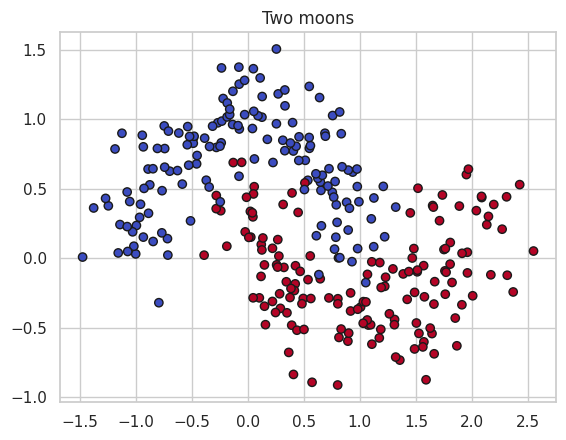


Shapes: X (300, 2) -> hidden (300, 8) -> output (300, 1)
First 5 predicted probabilities: [0.405 0.162 0.502 0.293 0.376]
Accuracy with random weights: 0.407 (random weights, so near 0.5 give or take chance)


In [5]:
Xm, ym = make_moons(n_samples=300, noise=0.2, random_state=42)
print('Data:', Xm.shape, ' labels:', ym.shape, ' class balance:', np.bincount(ym))
plt.scatter(Xm[:, 0], Xm[:, 1], c=ym, cmap='coolwarm', edgecolor='k'); plt.title('Two moons'); plt.show()

def init_params(n_in, n_hidden, n_out, seed=0):
    rng = np.random.RandomState(seed)
    return {'W1': rng.randn(n_in, n_hidden) * 0.5, 'b1': np.zeros(n_hidden),
            'W2': rng.randn(n_hidden, n_out) * 0.5, 'b2': np.zeros(n_out)}

def forward(X, p):
    Z1 = X @ p['W1'] + p['b1']; A1 = relu(Z1)          # hidden layer
    Z2 = A1 @ p['W2'] + p['b2']; A2 = sigmoid(Z2)      # output layer
    return A2, {'Z1': Z1, 'A1': A1, 'Z2': Z2}

params = init_params(2, 8, 1)
probs, cache = forward(Xm, params)
print('\nShapes: X', Xm.shape, '-> hidden', cache['A1'].shape, '-> output', probs.shape)
print('First 5 predicted probabilities:', probs[:5].ravel().round(3))
pred = (probs.ravel() > 0.5).astype(int)
print('Accuracy with random weights:', (pred == ym).mean().round(3), '(random weights, so near 0.5 give or take chance)')

### Count the parameters
Each layer has `n_in x n_out` weights plus `n_out` biases. For 2 -> 8 -> 1 that is (2x8 + 8) + (8x1 + 1) = 33 parameters. Training will adjust all of them.

In [6]:
def count_params(layer_sizes):
    return sum(i * o + o for i, o in zip(layer_sizes[:-1], layer_sizes[1:]))
print('2 -> 8 -> 1       :', count_params([2, 8, 1]))
print('30 -> 32 -> 16 -> 1 (Breast Cancer MLP planned for Day 4):', count_params([30, 32, 16, 1]))

2 -> 8 -> 1       : 33
30 -> 32 -> 16 -> 1 (Breast Cancer MLP planned for Day 4): 1537


## 5. Why do we need a non-linear activation?
If we stack layers **without** activation functions, the result is still just one linear function, so extra layers add nothing. Check it numerically:

In [7]:
rng = np.random.RandomState(1)
W1, W2 = rng.randn(2, 5), rng.randn(5, 1)
Xs = rng.randn(4, 2)
two_layers = (Xs @ W1) @ W2          # two linear layers, no activation
one_layer  = Xs @ (W1 @ W2)          # a single layer with the combined weights
print('Same output?', np.allclose(two_layers, one_layer))

Same output? True


The classic example is **XOR**: the output is 1 only when exactly one input is 1. No straight line separates the two classes, so a linear model fails, but a tiny network with a ReLU hidden layer solves it:

In [8]:
Xx = np.array([[0, 0], [0, 1], [1, 0], [1, 1]]); yx = np.array([0, 1, 1, 0])

lin = LogisticRegression().fit(Xx, yx)
print('Logistic regression (linear) accuracy on XOR:', lin.score(Xx, yx), ' <- cannot get 100%')

# A 2-2-1 network with hand-chosen weights and ReLU in the hidden layer
W1x = np.array([[1, 1], [1, 1]]); b1x = np.array([0, -1])
W2x = np.array([[1], [-2]]);      b2x = np.array([0])
hidden = relu(Xx @ W1x + b1x); out = hidden @ W2x + b2x
print('Hidden layer outputs:\n', hidden)
print('Network output:', out.ravel(), ' expected:', yx)

Logistic regression (linear) accuracy on XOR: 0.5  <- cannot get 100%
Hidden layer outputs:
 [[0 0]
 [1 0]
 [1 0]
 [2 1]]
Network output: [0 1 1 0]  expected: [0 1 1 0]


The hidden layer bends the space so that the two classes become separable. That is what non-linear activations give a network. On Day 2 the network will **learn** weights like these by itself.

## 6. Softmax, the output layer for more than two classes
For 3 classes (like Iris) the output layer has 3 neurons, and **softmax** turns their raw scores into probabilities that are positive and sum to 1:

softmax(z_i) = e^(z_i) / sum of e^(z_j)

In [9]:
def softmax(z):
    z = z - z.max(axis=1, keepdims=True)       # subtract the max for numerical stability
    e = np.exp(z)
    return e / e.sum(axis=1, keepdims=True)

scores = np.array([[2.0, 1.0, 0.1], [0.5, 0.5, 0.5], [-1.0, 3.0, 0.0]])
p = softmax(scores)
print(p.round(3)); print('Row sums:', p.sum(axis=1))

[[0.659 0.242 0.099]
 [0.333 0.333 0.333]
 [0.017 0.936 0.047]]
Row sums: [1. 1. 1.]
